# Phát triển và kiểm thử ngoài

XGBoost là mô hình chính, LR là tham chiếu, chọn từ kết quả NHANES. Số đếm và metric chưa áp trọng số khảo sát.

## Đọc NHANES

In [1]:
from pathlib import Path
import sys
from time import perf_counter
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
assert (project_dir / "src/utils.py").is_file()
sys.path.insert(0, str(project_dir))
from src.utils import prepare_final_run, fit_final_development, get_youden_threshold

data_path = project_dir / "data/processed/nhanes_2015_2018.parquet"
nhanes = pd.read_parquet(data_path)
input_cols = [
    "age", "sex", "race_ethnicity", "bmi", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
X = nhanes[input_cols].copy()
y = nhanes["diabetes_label"].copy()
support = nhanes.drop(columns=input_cols + ["diabetes_label"]).copy()
X_before, y_before, support_before = X.copy(deep=True), y.copy(deep=True), support.copy(deep=True)

assert X.shape == (10832, 8)
assert X.index.is_unique and X.index.equals(y.index) and X.index.equals(support.index)
assert support["SEQN"].notna().all() and support["SEQN"].is_unique
assert support["cycle"].notna().all()
assert y.notna().all() and y.value_counts().to_dict() == {0: 8558, 1: 2274}
assert str(Path(sys.executable).resolve()).lower() == str((project_dir.parent / ".venv/Scripts/python.exe").resolve()).lower()
pd.crosstab(support["cycle"], y)


diabetes_label,0,1
cycle,,
2015-2016,4397,1105
2017-2018,4161,1169


## CV phát triển

Tìm tham số trên toàn NHANES bằng CV 5-fold phân tầng nhãn × chu kỳ, 30 trial COMPLETE và objective ROC-AUC trung bình. Dùng miền tìm kiếm và pipeline ở notebook 03.

In [2]:
SEED, BUDGET = 42, 30
strata = y.astype("string") + "|" + support["cycle"].astype("string")
assert strata.nunique() == 4
splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, strata))
run = prepare_final_run(
    X, y, support, splits, data_path,
    project_dir / "results", project_dir / "models", seed=SEED, budget=BUDGET,
)
run_started = perf_counter()
fold_rows = []
for fold, (train, valid) in enumerate(splits, 1):
    for partition, indices in [("train", train), ("valid", valid)]:
        counts = support.iloc[indices][["cycle"]].assign(diabetes_label=y.iloc[indices])
        for (cycle, label), n in counts.value_counts().items():
            fold_rows.append({"fold": fold, "phần": partition, "cycle": cycle,
                              "nhãn": label, "số người": n})
pd.DataFrame(fold_rows).pivot(index=["fold", "phần", "cycle"], columns="nhãn", values="số người")


nhãn                     0    1
fold phần  cycle               
1    train 2015-2016  3517  884
           2017-2018  3329  935
     valid 2015-2016   880  221
           2017-2018   832  234
2    train 2015-2016  3517  884
           2017-2018  3329  935
     valid 2015-2016   880  221
           2017-2018   832  234
3    train 2015-2016  3518  884
           2017-2018  3328  936
     valid 2015-2016   879  221
           2017-2018   833  233
4    train 2015-2016  3518  884
           2017-2018  3329  935
     valid 2015-2016   879  221
           2017-2018   832  234
5    train 2015-2016  3518  884
           2017-2018  3329  935
     valid 2015-2016   879  221
           2017-2018   832  234

## Chọn ngưỡng

OOF của cấu hình được chọn dùng để phát triển ngưỡng, không phải đánh giá nội bộ độc lập vì CV chọn tham số dùng cùng mẫu. Tối đa hóa Youden J trong các ngưỡng hữu hạn, hòa thì lấy ngưỡng cao hơn; giữ cả ngưỡng 0,5 và Youden cho mọi nhóm.

In [3]:
threshold_check, candidates_check = get_youden_threshold(
    pd.Series([1, 0, 1, 0]), np.array([0.9, 0.8, 0.7, 0.6])
)
assert threshold_check == 0.9
assert np.isfinite(candidates_check["threshold"]).all()
threshold_constant, _ = get_youden_threshold(
    pd.Series([0, 1]), np.array([0.5, 0.5])
)
assert threshold_constant == 0.5
summaries = {}


## XGBoost cuối

In [4]:
summaries["XGBoost"] = fit_final_development("XGBoost", X, y, support, splits, run)
pd.DataFrame([{
    "Mô hình": "XGBoost",
    "Tham số": summaries["XGBoost"]["best_params"],
    "Youden": summaries["XGBoost"]["thresholds"]["youden"],
    "Thời gian (giây)": summaries["XGBoost"]["wall_seconds"],
}])


D:\NCKH Mini\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Mô hình,Tham số,Youden,Thời gian (giây)
0,XGBoost,"{'learning_rate': 0.06707295148238462, 'max_de...",0.489961,69.878967


## LR tham chiếu

In [5]:
summaries["LR"] = fit_final_development("LR", X, y, support, splits, run)
pd.DataFrame([{
    "Mô hình": "LR",
    "Tham số": summaries["LR"]["best_params"],
    "Youden": summaries["LR"]["thresholds"]["youden"],
    "Thời gian (giây)": summaries["LR"]["wall_seconds"],
}])


,Mô hình,Tham số,Youden,Thời gian (giây)
0,LR,{'C': 91.91723538975099},0.506633,26.218816


## Đối chiếu pipeline

In [6]:
pd.testing.assert_frame_equal(X, X_before)
pd.testing.assert_series_equal(y, y_before)
pd.testing.assert_frame_equal(support, support_before)
summary = pd.DataFrame([{
    "Mô hình": model,
    "Vai trò": item["role"],
    "Trial hoàn tất": item["complete_trials"],
    "Trial lỗi": item["failed_trials"],
    "Cảnh báo": item["warning_count"],
    "Ngưỡng 0.5": item["thresholds"]["default"],
    "Ngưỡng Youden": item["thresholds"]["youden"],
    "CV tìm tham số (giây)": item["trial_seconds"],
    "OOF phát triển (giây)": item["oof_seconds"],
    "Fit toàn mẫu (giây)": item["final_fit_seconds"],
    "Tổng mô hình (giây)": item["wall_seconds"],
    "Pipeline": item["pipeline_path"],
} for model, item in summaries.items()])
assert summary["Trial hoàn tất"].eq(30).all()
summary.to_csv(run["directory"] / "summary.csv", index=False)
display(summary)
display(pd.DataFrame([{
    "run_id": run["id"], "Kết quả": str(run["directory"]),
    "Pipeline": str(run["model_directory"]),
    "Thời gian phiên (giây)": perf_counter() - run_started,
}]))


,Mô hình,Vai trò,Trial hoàn tất,Trial lỗi,Cảnh báo,Ngưỡng 0.5,Ngưỡng Youden,CV tìm tham số (giây),OOF phát triển (giây),Fit toàn mẫu (giây),Tổng mô hình (giây),Pipeline
0,XGBoost,primary,30,0,0,0.5,0.489961,63.670351,1.370050,0.310891,69.878967,D:\NCKH Mini\diabetes-project\models\final\54c...
1,LR,reference,30,0,0,0.5,0.506633,22.617323,0.563342,0.119474,26.218816,D:\NCKH Mini\diabetes-project\models\final\54c...


,run_id,Kết quả,Pipeline,Thời gian phiên (giây)
0,54c463bbe9079503,D:\NCKH Mini\diabetes-project\results\final_de...,D:\NCKH Mini\diabetes-project\models\final\54c...,97.124168


## Đọc BRFSS

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from src.utils import check_external_inputs, evaluate_external_pipeline, save_png

final_run_id = "54c463bbe9079503"
final_results_dir = project_dir / "results/final_development" / final_run_id
final_models_dir = project_dir / "models/final" / final_run_id
external_dir = project_dir / "results/external_validation" / final_run_id
external_figures_dir = project_dir / "results/figures/external_validation" / final_run_id
external_dir.mkdir(parents=True, exist_ok=True)
external_figures_dir.mkdir(parents=True, exist_ok=True)
frozen_paths = [p for directory in [final_results_dir, final_models_dir]
                for p in directory.rglob("*") if p.is_file()]
frozen_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in frozen_paths}
config = json.loads((final_results_dir / "config.json").read_text(encoding="utf-8"))
input_cols = [
    "age", "sex", "race_ethnicity", "bmi", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
assert config["columns"] == input_cols
final_models, final_metadata, final_thresholds = {}, {}, {}
for model in ["XGBoost", "LR"]:
    manifest = json.loads((final_results_dir / model / "artifacts.json").read_text(encoding="utf-8"))
    assert manifest["run_id"] == final_run_id
    for filename, digest in manifest["sha256"].items():
        assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == digest
    final_metadata[model] = json.loads((final_models_dir / f"{model}.metadata.json").read_text(encoding="utf-8"))
    assert final_metadata[model]["config"] == config
    assert final_metadata[model]["run_id"] == final_run_id and final_metadata[model]["model"] == model
    final_thresholds[model] = json.loads((final_results_dir / model / "thresholds.json").read_text(encoding="utf-8"))
    assert final_thresholds[model] == final_metadata[model]["thresholds"]
    assert final_thresholds[model]["default"] == 0.5
    assert np.isfinite(final_thresholds[model]["youden"])
    final_models[model] = joblib.load(final_models_dir / f"{model}.joblib")
    assert final_models[model].feature_names_in_.tolist() == input_cols

brfss_sources, brfss_X, source_hashes, input_rows = {}, {}, {}, []
for year, expected_n in [(2015, 440658), (2017, 449219)]:
    source_path = project_dir / f"data/processed/brfss_{year}.parquet"
    source_hashes[str(source_path)] = hashlib.sha256(source_path.read_bytes()).hexdigest()
    source = pd.read_parquet(source_path)
    assert len(source) == expected_n
    brfss_sources[year] = source
    brfss_X[year] = check_external_inputs(source, input_cols, year)
    assert brfss_X[year].dtypes.astype(str).to_dict() == config["dtypes"]
    for column in input_cols:
        observed = brfss_X[year][column].dropna()
        input_rows.append({
            "year": year, "input": column, "dtype": str(source[column].dtype),
            "n": len(source), "missing": int(source[column].isna().sum()),
            "missing_percent": float(source[column].isna().mean() * 100),
            "observed": (f"{observed.min():g}–{observed.max():g}" if column in ["age", "bmi"]
                         else ", ".join(map(str, sorted(observed.unique())))),
        })
input_checks = pd.DataFrame(input_rows)
input_checks.to_csv(external_dir / "input_checks.csv", index=False)
display(input_checks.round({"missing_percent": 2}))


,year,input,dtype,n,missing,missing_percent,observed
0,2015,age,float64,440658,0,0.00,18–80
1,2015,sex,Int64,440658,0,0.00,"1, 2"
2,2015,race_ethnicity,string,440658,7341,1.67,"Black NH, Hispanic, Other, White NH"
3,2015,bmi,float64,440658,36191,8.21,12.02–99.95
4,2015,smoking_status,string,440658,17888,4.06,"current, former, never"
5,2015,physical_activity,Int64,440658,53031,12.03,"0, 1"
6,2015,heart_attack,Int64,440658,2090,0.47,"0, 1"
7,2015,stroke,Int64,440658,1152,0.26,"0, 1"
8,2017,age,float64,449219,0,0.00,18–80
9,2017,sex,Int64,449219,276,0.06,"1, 2"


## Metric ngoài mẫu

Dùng pipeline cuối và hai ngưỡng NHANES cho từng năm, gồm cả người thiếu đầu vào. ROC-AUC/AP/Brier dùng xác suất; các metric phân loại tính theo từng ngưỡng.

In [2]:
external_predictions, probability_rows, threshold_rows, calibration_rows = {}, [], [], []
for year, source in brfss_sources.items():
    for model, pipeline in final_models.items():
        prediction, metrics, by_threshold, groups = evaluate_external_pipeline(
            pipeline, source, brfss_X[year], final_thresholds[model], model, year
        )
        path = external_dir / f"brfss_{year}_{model}_predictions.parquet"
        prediction.to_parquet(path, index=True)
        pd.testing.assert_frame_equal(pd.read_parquet(path), prediction)
        pd.testing.assert_frame_equal(
            prediction[["diabetes_label", "sex", "age", "bmi", "race_ethnicity"]],
            source[["diabetes_label", "sex", "age", "bmi", "race_ethnicity"]],
        )
        assert prediction["source_row_id"].tolist() == source.index.tolist()
        external_predictions[(year, model)] = prediction
        probability_rows.append(metrics)
        threshold_rows.extend(by_threshold)
        calibration_rows.append(groups)
probability_metrics = pd.DataFrame(probability_rows)
threshold_metrics = pd.DataFrame(threshold_rows)
external_calibration = pd.concat(calibration_rows, ignore_index=True)[[
    "year", "model", "quantile_group", "lower_bound", "upper_bound",
    "n", "mean_probability", "positive_rate",
]]
probability_metrics.to_csv(external_dir / "probability_metrics.csv", index=False)
threshold_metrics.to_csv(external_dir / "threshold_metrics.csv", index=False)
external_calibration.to_csv(external_dir / "calibration_quantile_bins.csv", index=False)
display(probability_metrics.round(6))
display(threshold_metrics.round(6))


,year,model,n,n_positive,positive_rate,roc_auc,average_precision,brier
0,2015,XGBoost,440658,57256,0.129933,0.770298,0.315484,0.184886
1,2015,LR,440658,57256,0.129933,0.770900,0.312760,0.181903
2,2017,XGBoost,449219,60440,0.134545,0.769057,0.321842,0.186524
3,2017,LR,449219,60440,0.134545,0.772248,0.329253,0.182747


,year,model,threshold_name,threshold,n,n_positive,sensitivity,specificity,ppv,npv,f1,tn,fp,fn,tp,predicted_positive_rate
0,2015,XGBoost,default,0.500000,440658,57256,0.701883,0.697706,0.257465,0.940018,0.376736,267502,115900,17069,40187,0.354213
1,2015,XGBoost,youden,0.489961,440658,57256,0.715279,0.685763,0.253690,0.941617,0.374541,262923,120479,16302,40954,0.366345
2,2015,LR,default,0.500000,440658,57256,0.669222,0.722860,0.265036,0.936035,0.379698,277146,106256,18939,38317,0.328084
3,2015,LR,youden,0.506633,440658,57256,0.658289,0.731144,0.267747,0.934759,0.380665,280322,103080,19565,37691,0.319456
4,2017,XGBoost,default,0.500000,449219,60440,0.708504,0.692146,0.263505,0.938551,0.384142,269092,119687,17618,42822,0.361759
5,2017,XGBoost,youden,0.489961,449219,60440,0.722105,0.680075,0.259749,0.940269,0.382065,264399,124380,16796,43644,0.374036
6,2017,LR,default,0.500000,449219,60440,0.678657,0.716132,0.270960,0.934790,0.387291,278417,110362,19422,41018,0.336985
7,2017,LR,youden,0.506633,449219,60440,0.668200,0.724383,0.273729,0.933525,0.388364,281625,107154,20054,40386,0.328437


## ROC và precision–recall

Đường tham chiếu PR là tỷ lệ nhãn 1 của từng năm.

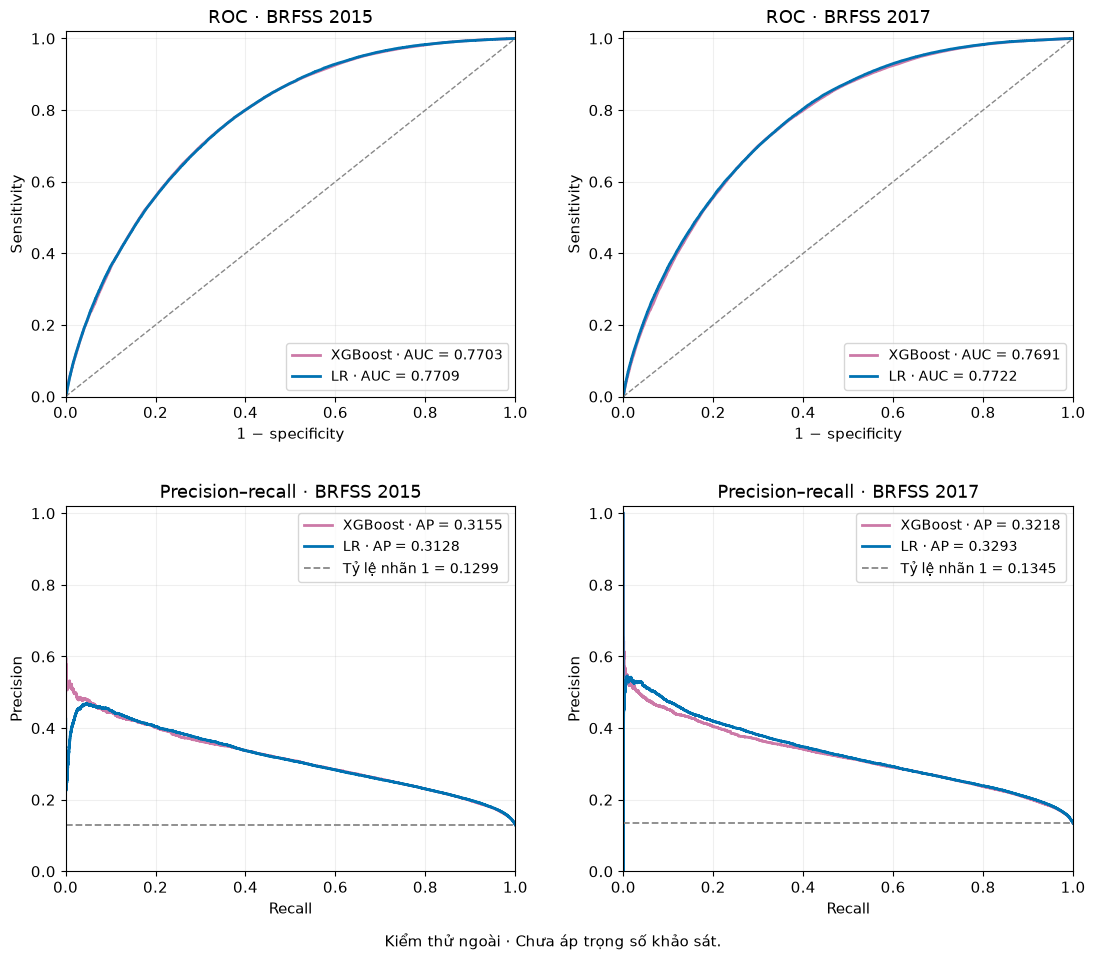

In [3]:
model_colors = {"XGBoost": "#CC79A7", "LR": "#0072B2"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 13, "axes.labelsize": 11, "legend.fontsize": 10})
figure_paths = []
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for column, year in enumerate([2015, 2017]):
    for model in ["XGBoost", "LR"]:
        prediction = external_predictions[(year, model)]
        y_true, probability = prediction["diabetes_label"], prediction["probability"]
        row = probability_metrics.query("year == @year and model == @model").iloc[0]
        fpr, tpr, _ = roc_curve(y_true, probability)
        precision, recall, _ = precision_recall_curve(y_true, probability, drop_intermediate=True)
        axes[0, column].plot(fpr, tpr, color=model_colors[model], linewidth=2,
                             label=f"{model} · AUC = {row['roc_auc']:.4f}")
        axes[1, column].step(recall, precision, where="post", color=model_colors[model],
                             linewidth=2, label=f"{model} · AP = {row['average_precision']:.4f}")
    prevalence = float(brfss_sources[year]["diabetes_label"].mean())
    axes[0, column].plot([0, 1], [0, 1], "--", color="#888888", linewidth=1)
    axes[1, column].axhline(prevalence, linestyle="--", color="#888888", linewidth=1.3,
                           label=f"Tỷ lệ nhãn 1 = {prevalence:.4f}")
    axes[0, column].set(title=f"ROC · BRFSS {year}", xlabel="1 − specificity", ylabel="Sensitivity")
    axes[1, column].set(title=f"Precision–recall · BRFSS {year}", xlabel="Recall", ylabel="Precision")
for ax in axes.flat:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.2)
    ax.legend(loc="lower right" if ax in axes[0] else "upper right")
fig.subplots_adjust(bottom=0.10, top=0.94, wspace=0.24, hspace=0.30)
fig.text(0.5, 0.025, "Kiểm thử ngoài · Chưa áp trọng số khảo sát.", ha="center")
figure_paths.append(save_png(fig, external_figures_dir / "brfss_roc_pr.png"))
plt.show()
plt.close(fig)


## Calibration

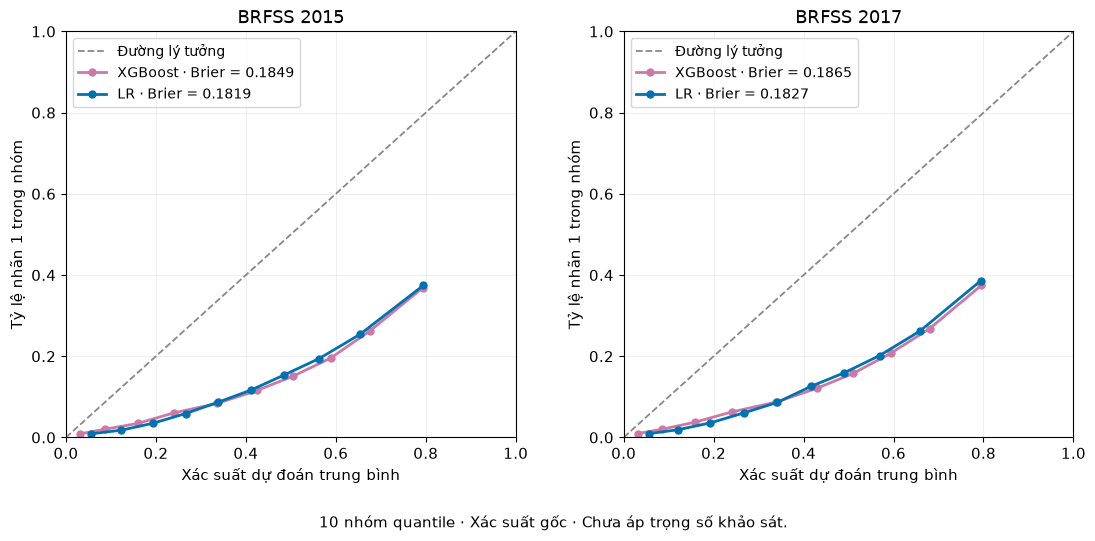

,year,model,quantile_group,n,mean_probability,positive_rate
0,2015,XGBoost,1,44071,0.032224,0.009008
1,2015,XGBoost,2,44061,0.087590,0.020335
2,2015,XGBoost,3,44066,0.159215,0.034403
3,2015,XGBoost,4,44087,0.239897,0.060494
4,2015,XGBoost,5,44051,0.335728,0.083585
5,2015,XGBoost,6,44061,0.424872,0.115839
6,2015,XGBoost,7,44066,0.504530,0.150570
7,2015,XGBoost,8,44072,0.588351,0.195362
8,2015,XGBoost,9,44068,0.675062,0.261709
9,2015,XGBoost,10,44055,0.792762,0.368085


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, year in zip(axes, [2015, 2017]):
    ax.plot([0, 1], [0, 1], "--", color="#888888", linewidth=1.3, label="Đường lý tưởng")
    for model in ["XGBoost", "LR"]:
        groups = external_calibration.query("year == @year and model == @model and n > 0")
        row = probability_metrics.query("year == @year and model == @model").iloc[0]
        ax.plot(groups["mean_probability"], groups["positive_rate"], marker="o", markersize=5,
                color=model_colors[model], linewidth=2, label=f"{model} · Brier = {row['brier']:.4f}")
    ax.set(title=f"BRFSS {year}", xlabel="Xác suất dự đoán trung bình",
           ylabel="Tỷ lệ nhãn 1 trong nhóm", xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
fig.subplots_adjust(bottom=0.20, top=0.90, wspace=0.24)
fig.text(0.5, 0.045, "10 nhóm quantile · Xác suất gốc · Chưa áp trọng số khảo sát.", ha="center")
figure_paths.append(save_png(fig, external_figures_dir / "brfss_calibration.png"))
plt.show()
plt.close(fig)
display(external_calibration[["year", "model", "quantile_group", "n",
                              "mean_probability", "positive_rate"]].round(6))


## Confusion matrix XGBoost

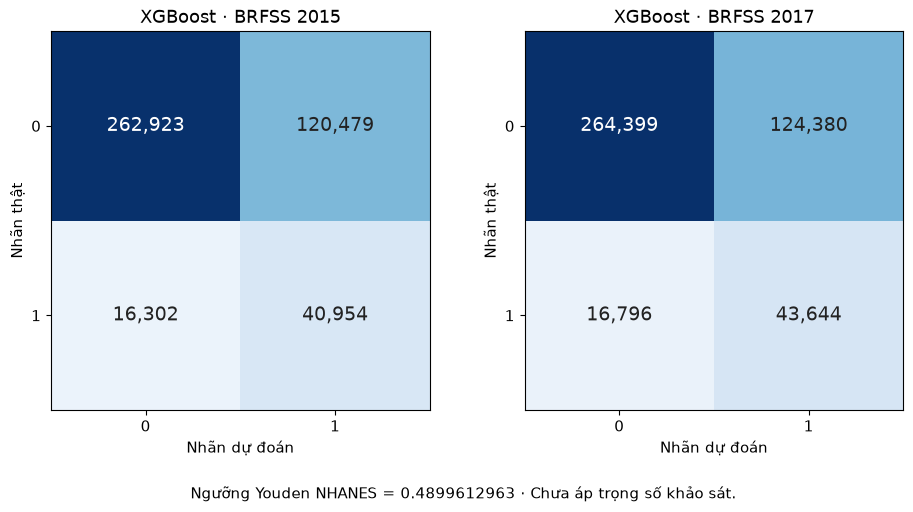

In [5]:
xgb_youden = threshold_metrics.query("model == 'XGBoost' and threshold_name == 'youden'").set_index("year")
vmax = xgb_youden[["tn", "fp", "fn", "tp"]].to_numpy().max()
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, year in zip(axes, [2015, 2017]):
    row = xgb_youden.loc[year]
    matrix = row[["tn", "fp", "fn", "tp"]].to_numpy(dtype=int).reshape(2, 2)
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
    for (i, j), count in np.ndenumerate(matrix):
        ax.text(j, i, f"{count:,}", ha="center", va="center", fontsize=14,
                color="white" if count > vmax / 2 else "#222222")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["0", "1"], yticklabels=["0", "1"],
           xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title=f"XGBoost · BRFSS {year}")
fig.subplots_adjust(bottom=0.20, top=0.90, wspace=0.25)
fig.text(0.5, 0.045,
         f"Ngưỡng Youden NHANES = {final_thresholds['XGBoost']['youden']:.10f} · Chưa áp trọng số khảo sát.",
         ha="center")
figure_paths.append(save_png(fig, external_figures_dir / "brfss_xgboost_confusion_youden.png"))
plt.show()
plt.close(fig)


## Nhận xét

Hai mô hình có ROC-AUC gần nhau; xác suất trung bình cao hơn tỷ lệ nhãn 1 ở cả 10 nhóm của từng năm. Khác biệt về cách đo đầu vào và định nghĩa nhãn khiến kết quả này phản ánh khả năng chuyển giữa hai khảo sát.

In [6]:
for filename, digest in {**frozen_hashes, **source_hashes}.items():
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == digest
for year in [2015, 2017]:
    for model in ["XGBoost", "LR"]:
        prediction = external_predictions[(year, model)]
        assert prediction["source_row_id"].is_unique and len(prediction) == len(brfss_sources[year])
        assert prediction["year"].eq(year).all()
        assert prediction["probability"].between(0, 1).all()
        for name, column in [("default", "prediction_0_5"), ("youden", "prediction_youden")]:
            np.testing.assert_array_equal(prediction[column],
                prediction["probability"].ge(final_thresholds[model][name]).astype(int))
    assert np.array_equal(external_predictions[(year, "XGBoost")]["source_row_id"],
                          external_predictions[(year, "LR")]["source_row_id"])
for (year, model), groups in external_calibration.groupby(["year", "model"]):
    assert len(groups) == 10 and groups["n"].sum() == len(brfss_sources[year])
external_config = {
    "final_run_id": final_run_id, "models": {"XGBoost": "primary", "LR": "reference"},
    "input_columns": input_cols, "thresholds": final_thresholds,
    "source_row_id": "index of processed BRFSS source before reset or sorting; unique within year",
    "survey_weighted": False, "calibration_bins": "10 quantile groups; equal probabilities stay together",
    "source_sha256": source_hashes, "frozen_artifact_sha256": frozen_hashes,
    "versions": config["versions"],
}
files = [p for p in external_dir.iterdir() if p.is_file() and p.name != "manifest.json"] + figure_paths
external_config["output_sha256"] = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in files}
(external_dir / "manifest.json").write_text(json.dumps(external_config, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame({"Hình": [str(p) for p in figure_paths]}))
display(probability_metrics[["year", "model", "n", "n_positive", "roc_auc", "average_precision", "brier"]].round(6))


,Hình
0,D:\NCKH Mini\diabetes-project\results\figures\...
1,D:\NCKH Mini\diabetes-project\results\figures\...
2,D:\NCKH Mini\diabetes-project\results\figures\...
3,D:\NCKH Mini\diabetes-project\results\figures\...
4,D:\NCKH Mini\diabetes-project\results\figures\...
5,D:\NCKH Mini\diabetes-project\results\figures\...


,year,model,n,n_positive,roc_auc,average_precision,brier
0,2015,XGBoost,440658,57256,0.770298,0.315484,0.184886
1,2015,LR,440658,57256,0.770900,0.312760,0.181903
2,2017,XGBoost,449219,60440,0.769057,0.321842,0.186524
3,2017,LR,449219,60440,0.772248,0.329253,0.182747
